# Reinforcement Learning Agent Control for Cooling Distribution Units

The mathematical formulation behind the Python Proximal Policy Optimization (PPO) controller recasts the cooling distribution unit (CDU) thermal control problem as a continuous-action Markov decision process (MDP) and solves it via actor-critic policy gradient optimization.

An MDP is defined by the tuple $(\mathcal{O}, \mathcal{A}, P, R, \gamma)$, where every element maps directly to the physical CDU environment:

#### Observation Space ($\mathbf{o}_k \in \mathcal{O} \subset \mathbb{R}^4$)

Because neural networks train poorly when inputs span mismatched physical units (e.g., temperatures in ${}^\circ\text{C}$, power in $\text{kW}$, flow in $\text{kg/s}$), the raw physical variables are affine-normalized into dimensionless quantities centered near $[-1, 1]$:


$$\mathbf{o}_k = \begin{bmatrix} o_{1,k} \\ o_{2,k} \\ o_{3,k} \\ o_{4,k} \end{bmatrix} = \begin{bmatrix} \dfrac{T_{\text{chip},k} - 55.0}{30.0} \\ \dfrac{T_{\text{cdu},k} - 45.0}{20.0} \\ \dfrac{Q_{\text{IT},k} - 50.0}{50.0} \\ \dfrac{u_{k-1} - 1.5}{1.5} \end{bmatrix}$$

* **Markovian Augmentation ($o_{4,k}$):** Including the previous pump mass flow rate $u_{k-1}$ in $\mathbf{o}_k$ is mathematically required so the environment satisfies the **Markov property** ($P(\mathbf{o}_{k+1}, r_k \mid \mathbf{o}_k, a_k) = P(\mathbf{o}_{k+1}, r_k \mid \mathbf{o}_0, a_0, \dots, \mathbf{o}_k, a_k)$). Without $u_{k-1}$ in the observation vector, the reward's slew-rate penalty $(u_k - u_{k-1})^2$ would depend on unmeasured history.

#### Continuous Action Space and Actuator Mapping ($a_k \in \mathcal{A} = [-1, 1]$)

The policy network outputs a normalized action $a_k$, which is clipped to $[-1, 1]$ and affinely mapped onto the physical VFD pump flow bounds $[\dot{m}_{\min}, \dot{m}_{\max}] = [0.35, 3.0]\text{ kg/s}$:


$$u_k = \dot{m}_{\min} + \frac{1}{2}\Big(\text{clip}(a_k, -1, 1) + 1\Big)(\dot{m}_{\max} - \dot{m}_{\min})$$

#### Black-Box Transition Dynamics ($P$)

Between discrete steps $t_k$ and $t_{k+1} = t_k + \Delta t$, the physical state $\mathbf{x}_k = [T_{\text{chip},k},\, T_{\text{cdu},k}]^T$ evolves via 4th-order Runge-Kutta (`rk4_step`) integration of the nonlinear CDU energy balances:


$$\mathbf{x}_{k+1} = \mathbf{F}_{\text{RK4}}(\mathbf{x}_k, u_k, Q_{\text{IT},k};\, \Delta t)$$


Unlike MPC, the PPO agent never accesses the equations inside $\mathbf{F}_{\text{RK4}}$ or computes Jacobians; it treats the state transition $P(\mathbf{o}_{k+1} \mid \mathbf{o}_k, a_k)$ purely as a black-box simulator.

#### Reward Function ($r_k$)

Reinforcement learning maximizes cumulative reward, whereas MPC minimizes cumulative cost. Setting the scalar reward $r_k$ equal to the negated MPC stage cost aligns both controllers to the exact same physical objective:


$$r_k = -\alpha \left[ w_T \Big(\max\big(0,\; T_{\text{chip},k+1} - T_{\text{soft}}\big)\Big)^2 + w_u \, u_k^3 + w_{\Delta u} (u_k - u_{k-1})^2 \right]$$


with $\alpha = 0.02$ (gradient-conditioning scale factor), $w_T = 250.0$, $w_u = 1.0$, $w_{\Delta u} = 3.0$, and $T_{\text{soft}} = 80.0^\circ\text{C}$.

### 2. Discounted Return and Value Functions

While MPC optimizes over a hard finite look-ahead window of $N_p = 16$ steps ($8\text{ s}$), RL optimizes the **discounted return** $G_k$ over the remainder of an episode of length $T = 150$ steps ($75\text{ s}$):


$$G_k = \sum_{l=0}^{T - k - 1} \gamma^l r_{k+l}$$


where $\gamma = 0.99$ is the discount factor (corresponding to an effective exponential time horizon of $\frac{1}{1-\gamma} = 100\text{ steps} = 50\text{ s}$).

For a given control policy $\pi_\theta(a \mid \mathbf{o})$, we define two value functions:

1. **State-Value Function ($V^{\pi_\theta}$):** Expected return starting from observation $\mathbf{o}_k$ and following $\pi_\theta$:

$$V^{\pi_\theta}(\mathbf{o}_k) = \mathbb{E}_{\pi_\theta}\!\left[ G_k \,\middle\vert{}\, \mathbf{o}_k \right]$$


2. **Action-Value Function ($Q^{\pi_\theta}$):** Expected return after taking action $a_k$ at $\mathbf{o}_k$ and thereafter following $\pi_\theta$:

$$Q^{\pi_\theta}(\mathbf{o}_k, a_k) = \mathbb{E}_{\pi_\theta}\!\left[ G_k \,\middle\vert{}\, \mathbf{o}_k, a_k \right]$$


### 3. Stochastic Gaussian Actor-Critic Parameterization

To explore continuous pump speeds during training, the **Actor** parameterizes a univariate Gaussian policy $\pi_\theta(a_k \mid \mathbf{o}_k)$ using a 2-hidden-layer multilayer perceptron (`Tanh` activations, ending in `Tanh` so $\mu_\theta(\mathbf{o}_k) \in (-1, 1)$) paired with a state-independent learnable log-standard deviation $\log \sigma_\theta$:


$$\pi_\theta(a_k \mid \mathbf{o}_k) = \mathcal{N}\!\Big(\mu_\theta(\mathbf{o}_k),\, \sigma_\theta^2\Big), \qquad \sigma_\theta = \exp(\log \sigma_\theta)$$

Policy gradient updates require the log-likelihood of sampled actions (`dist.log_prob(action)`):


$$\log \pi_\theta(a_k \mid \mathbf{o}_k) = -\frac{1}{2} \left[ \left(\frac{a_k - \mu_\theta(\mathbf{o}_k)}{\sigma_\theta}\right)^2 + 2\log \sigma_\theta + \log(2\pi) \right]$$

Simultaneously, a separate **Critic** neural network $V_\phi(\mathbf{o}_k)$ (with weights $\phi$ and a linear scalar output) learns to approximate $V^{\pi_\theta}(\mathbf{o}_k)$. Once offline training finishes, stochastic sampling is turned off and the deployed controller becomes a deterministic state-feedback law:


$$a_k^* = \mu_\theta(\mathbf{o}_k)$$


### 4. Generalized Advantage Estimation (GAE)

To update the policy without high Monte Carlo variance, PPO evaluates the **Advantage Function**:


$$A^{\pi_\theta}(\mathbf{o}_k, a_k) = Q^{\pi_\theta}(\mathbf{o}_k, a_k) - V^{\pi_\theta}(\mathbf{o}_k)$$


Physically, $A^{\pi_\theta}(\mathbf{o}_k, a_k) > 0$ means the pump flow $a_k$ yielded a higher cumulative return (less thermal violation and/or lower pumping energy) than the Critic's baseline expectation $V^{\pi_\theta}(\mathbf{o}_k)$ at that thermal state.

At each step $k$, we first compute the 1-step **Temporal-Difference (TD) residual** $\delta_k$ using the Critic network $V_\phi$:


$$\delta_k = r_k + \gamma V_\phi(\mathbf{o}_{k+1}) - V_\phi(\mathbf{o}_k)$$


(with $V_\phi(\mathbf{o}_T) \equiv 0$ at the terminal step). **Generalized Advantage Estimation (GAE)** forms an exponentially weighted sum of multi-step TD residuals (`gae = delta + gamma * lam * gae`):


$$\hat{A}_k = \sum_{l=0}^{T - k - 1} (\gamma \lambda)^l \delta_{k+l}$$


where $\lambda = 0.95$ controls the bias-variance trade-off ($\lambda = 0$ reduces to low-variance 1-step TD; $\lambda = 1$ recovers unbiased Monte Carlo returns). From $\hat{A}_k$, the target return for training the Critic is reconstructed as:


$$\hat{R}_k = \hat{A}_k + V_\phi(\mathbf{o}_k)$$


Before each gradient update, $\hat{A}_k$ is standardized across the batch ($\tilde{A}_k = \frac{\hat{A}_k - \mu_A}{\sigma_A + 10^{-8}}$) to keep step sizes invariant to reward scaling.

### 5. PPO-Clip Objective Function

In standard policy gradients, a single noisy batch of episodes can cause an overly large gradient step that collapses the policy (for example, suddenly commanding minimum pump flow $\dot{m}_{\min}$ during a $100\text{ kW}$ thermal surge). PPO prevents destructive updates by constraining the probability ratio between the candidate policy $\pi_\theta$ and the data-collection policy $\pi_{\theta_{\text{old}}}$:


$$\rho_k(\theta) = \frac{\pi_\theta(a_k \mid \mathbf{o}_k)}{\pi_{\theta_{\text{old}}}(a_k \mid \mathbf{o}_k)} = \exp\!\Big(\log \pi_\theta(a_k \mid \mathbf{o}_k) - \log \pi_{\theta_{\text{old}}}(a_k \mid \mathbf{o}_k)\Big)$$

The total minimized loss combines three terms over the batch of collected transitions:


$$\mathcal{L}_{\text{total}}(\theta, \phi) = -\mathcal{L}^{\text{CLIP}}(\theta) + c_1 \mathcal{L}^{\text{VF}}(\phi) - c_2 \hat{\mathbb{E}}_k\!\left[\mathcal{H}\big(\pi_\theta(\cdot \mid \mathbf{o}_k)\big)\right]$$

1. **Clipped Surrogate Actor Objective ($\mathcal{L}^{\text{CLIP}}$):**

$$\mathcal{L}^{\text{CLIP}}(\theta) = \hat{\mathbb{E}}_k \left[ \min\!\Big(\rho_k(\theta)\tilde{A}_k,\; \text{clip}\big(\rho_k(\theta),\, 1-\epsilon,\, 1+\epsilon\big)\tilde{A}_k\Big) \right]$$



With $\epsilon = 0.2$, whenever $\rho_k(\theta)$ leaves the trust interval $[0.8, 1.2]$ in the direction that improves the objective, the gradient with respect to $\theta$ becomes zero—acting as a soft trust-region constraint on policy updates.
2. **Critic Value-Function Loss ($\mathcal{L}^{\text{VF}}$ with $c_1 = 0.5$):**

$$\mathcal{L}^{\text{VF}}(\phi) = \hat{\mathbb{E}}_k \left[ \big(V_\phi(\mathbf{o}_k) - \hat{R}_k\big)^2 \right]$$



Trains the Critic via mean-squared error to accurately predict future cumulative thermal and pumping costs.
3. **Differential Entropy Bonus ($\mathcal{H}$ with $c_2 = 0.005$):**

$$\mathcal{H}\big(\pi_\theta(\cdot \mid \mathbf{o}_k)\big) = \frac{1}{2}\big(1 + \log(2\pi\sigma_\theta^2)\big)$$



Rewards policy variance slightly during training so $\sigma_\theta$ does not collapse prematurely before the agent has experienced both idle ($15\text{ kW}$) and full-throttle ($100\text{ kW}$) operating regimes.

| Mathematical Property | Physics-Based MPC | Model-Free PPO (RL) |
| --- | --- | --- |
| **Where physics enters** | Explicitly inside the equality constraints $\mathbf{x}_{k+j+1 \mid k} = A_d \mathbf{x}_{k+j \mid k} + \mathbf{B}_{u,d}u_{k+j \mid k} + \mathbf{B}_{d,d}d_{k \mid k} + \mathbf{c}_d$. | Implicitly inside the environment simulator $\mathbf{F}_{\text{RK4}}$ that generates $(\mathbf{o}_{k+1}, r_k)$ training samples. |
| **What is optimized** | A sequence of future pump flows $\mathbf{U}_k \in \mathbb{R}^{N_p}$ at every real-time step $k$. | Neural network weights $(\theta, \phi)$ offline across hundreds of randomized episodes. |
| **How future risk is foreseen** | Explicit multi-step forward rollout using conservation of energy & Newton's cooling law. | Encoded inside the Critic $V_\phi(\mathbf{o}_k)$ and Actor $\mu_\theta(\mathbf{o}_k)$ via TD/GAE backpropagation of future thermal penalties. |

In [2]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["OMP_NUM_THREADS"] = "1"

import time
import numpy as np
import torch
import torch.nn as nn
from torch.distributions import Normal

torch.set_num_threads(1)

torch.manual_seed(42)
np.random.seed(42)

# ==============================================================================
# 1. Identical CDU Physics & Parameters
# ==============================================================================
C_chip, C_cdu, R_th, cp = 12.0, 35.0, 0.40, 4.18
T_fac, T_throttle, T_soft_cap = 30.0, 85.0, 80.0
m_min, m_max = 0.35, 3.0
dt = 0.5

def cdu_ode(x, u_mdot, q_it):
    T_chip, T_cdu = x
    q_conv = (T_chip - T_cdu) / R_th
    dT_chip = (q_it - q_conv) / C_chip
    dT_cdu  = (q_conv - u_mdot * cp * (T_cdu - T_fac)) / C_cdu
    return np.array([dT_chip, dT_cdu], dtype=np.float32)

def rk4_step(x, u, q_it, dt):
    k1 = cdu_ode(x, u, q_it)
    k2 = cdu_ode(x + 0.5 * dt * k1, u, q_it)
    k3 = cdu_ode(x + 0.5 * dt * k2, u, q_it)
    k4 = cdu_ode(x + dt * k3, u, q_it)
    return x + (dt / 6.0) * (k1 + 2*k2 + 2*k3 + k4)

# ==============================================================================
# 2. Gymnasium-Style CDU Environment with Randomized Workload Surges
# ==============================================================================
class CDUEnv:
    def __init__(self):
        self.N_steps = int(75.0 / dt)
        self.reset()

    def _sample_workload(self):
        """Randomize surge timing, ramp rate, and power so policy generalizes."""
        t_grid = np.arange(self.N_steps) * dt
        t_start = np.random.uniform(5.0, 20.0)
        ramp_up = np.random.uniform(3.0, 8.0)
        hold_dur = np.random.uniform(20.0, 40.0)
        ramp_dn = np.random.uniform(3.0, 8.0)
        q_idle = np.random.uniform(10.0, 25.0)
        q_peak = np.random.uniform(70.0, 110.0)

        q = np.full(self.N_steps, q_idle, dtype=np.float32)
        for k, t in enumerate(t_grid):
            if t_start <= t < t_start + ramp_up:
                q[k] = q_idle + (q_peak - q_idle) * (t - t_start) / ramp_up
            elif t_start + ramp_up <= t < t_start + ramp_up + hold_dur:
                q[k] = q_peak
            elif t_start + ramp_up + hold_dur <= t < t_start + ramp_up + hold_dur + ramp_dn:
                q[k] = q_peak - (q_peak - q_idle) * (t - (t_start + ramp_up + hold_dur)) / ramp_dn
        return q

    def reset(self, fixed_profile=None):
        self.q_profile = self._sample_workload() if fixed_profile is None else fixed_profile
        self.k = 0
        self.u_prev = 0.4
        q0 = self.q_profile[0]
        T_cdu0 = T_fac + q0 / (self.u_prev * cp)
        T_chip0 = T_cdu0 + q0 * R_th
        self.x = np.array([T_chip0, T_cdu0], dtype=np.float32)
        return self._get_obs()

    def _get_obs(self):
        """Normalized observation vector: [T_chip, T_cdu, Q_IT, u_prev]."""
        q_curr = self.q_profile[self.k]
        return np.array([
            (self.x[0] - 55.0) / 30.0,
            (self.x[1] - 45.0) / 20.0,
            (q_curr - 50.0) / 50.0,
            (self.u_prev - 1.5) / 1.5
        ], dtype=np.float32)

    def step(self, action_norm):
        a = float(np.clip(action_norm, -1.0, 1.0))
        u = m_min + 0.5 * (a + 1.0) * (m_max - m_min)

        q_curr = self.q_profile[self.k]
        self.x = rk4_step(self.x, u, q_curr, dt)

        # Reward = negative of MPC stage cost (with higher barrier weight to enforce safety)
        violation = max(0.0, float(self.x[0]) - T_soft_cap)
        stage_cost = (
            250.0 * (violation ** 2)
            + 1.0 * (u ** 3)
            + 3.0 * ((u - self.u_prev) ** 2)
        )
        reward = -0.02 * stage_cost

        self.u_prev = u
        self.k += 1
        done = (self.k >= self.N_steps - 1)
        return self._get_obs(), reward, done, {"T_chip": self.x[0], "T_cdu": self.x[1], "u": u}

# ==============================================================================
# 3. Continuous Actor-Critic Neural Network (PPO)
# ==============================================================================
class ActorCritic(nn.Module):
    def __init__(self, obs_dim=4, act_dim=1):
        super().__init__()
        self.actor_mean = nn.Sequential(
            nn.Linear(obs_dim, 64), nn.Tanh(),
            nn.Linear(64, 64), nn.Tanh(),
            nn.Linear(64, act_dim), nn.Tanh()
        )
        self.actor_logstd = nn.Parameter(torch.full((act_dim,), -0.7))
        self.critic = nn.Sequential(
            nn.Linear(obs_dim, 64), nn.Tanh(),
            nn.Linear(64, 64), nn.Tanh(),
            nn.Linear(64, 1)
        )

    def act(self, obs_t):
        mean = self.actor_mean(obs_t)
        dist = Normal(mean, torch.exp(self.actor_logstd))
        action = dist.sample()
        return action, dist.log_prob(action).sum(-1), self.critic(obs_t).squeeze(-1)

    def evaluate(self, obs_t, act_t):
        mean = self.actor_mean(obs_t)
        dist = Normal(mean, torch.exp(self.actor_logstd))
        return dist.log_prob(act_t).sum(-1), dist.entropy().sum(-1), self.critic(obs_t).squeeze(-1)

# ==============================================================================
# 4. Offline PPO Training Loop
# ==============================================================================
t0 = time.time()
env = CDUEnv()
ac = ActorCritic()
optimizer = torch.optim.Adam(ac.parameters(), lr=5e-4)
gamma, lam, clip_eps = 0.99, 0.95, 0.2

for epoch in range(55):  # 55 epochs x 8 episodes = 440 episodes
    obs_buf, act_buf, logp_buf, ret_buf, adv_buf = [], [], [], [], []
    for _ in range(8):
        obs = env.reset()
        ep_obs, ep_act, ep_logp, ep_rew, ep_val = [], [], [], [], []
        done = False
        while not done:
            with torch.no_grad():
                act_t, logp_t, val_t = ac.act(torch.tensor(obs))
            next_obs, rew, done, _ = env.step(act_t.item())
            ep_obs.append(obs); ep_act.append(act_t.numpy())
            ep_logp.append(logp_t.item()); ep_rew.append(rew); ep_val.append(val_t.item())
            obs = next_obs

        # Generalized Advantage Estimation (GAE)
        gae = 0.0
        ep_adv = np.zeros(len(ep_rew), dtype=np.float32)
        for t in reversed(range(len(ep_rew))):
            next_v = 0.0 if t == len(ep_rew) - 1 else ep_val[t + 1]
            delta = ep_rew[t] + gamma * next_v - ep_val[t]
            gae = delta + gamma * lam * gae
            ep_adv[t] = gae
        ep_ret = ep_adv + np.array(ep_val, dtype=np.float32)

        obs_buf.extend(ep_obs); act_buf.extend(ep_act); logp_buf.extend(ep_logp)
        ret_buf.extend(ep_ret); adv_buf.extend(ep_adv)

    obs_b = torch.tensor(np.array(obs_buf))
    act_b = torch.tensor(np.array(act_buf))
    logp_old = torch.tensor(np.array(logp_buf))
    ret_b = torch.tensor(np.array(ret_buf))
    adv_b = (torch.tensor(np.array(adv_buf)) - np.mean(adv_buf)) / (np.std(adv_buf) + 1e-8)

    for _ in range(6):
        logp_new, ent, val_new = ac.evaluate(obs_b, act_b)
        ratio = torch.exp(logp_new - logp_old)
        surr1 = ratio * adv_b
        surr2 = torch.clamp(ratio, 1.0 - clip_eps, 1.0 + clip_eps) * adv_b
        loss = -torch.min(surr1, surr2).mean() + 0.5 * ((val_new - ret_b) ** 2).mean() - 0.005 * ent.mean()
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

# ==============================================================================
# 5. Evaluate Deterministic Policy
# ==============================================================================
t_grid = np.arange(env.N_steps) * dt
q_bench = np.zeros(env.N_steps, dtype=np.float32)
for k, t in enumerate(t_grid):
    if t < 10.0: q_bench[k] = 15.0
    elif t < 15.0: q_bench[k] = 15.0 + 85.0 * (t - 10.0) / 5.0
    elif t < 50.0: q_bench[k] = 100.0
    elif t < 55.0: q_bench[k] = 100.0 - 85.0 * (t - 50.0) / 5.0
    else: q_bench[k] = 15.0

obs = env.reset(fixed_profile=q_bench)
hist_rl = []
done = False
while not done:
    with torch.no_grad():
        det_act = ac.actor_mean(torch.tensor(obs)).item()  # Deterministic deployment
    obs, _, done, info = env.step(det_act)
    hist_rl.append([info["T_chip"], info["T_cdu"], info["u"]])
hist_rl = np.array(hist_rl)

print(f"Training time: {time.time() - t0:.1f} s")
print(f"RL Policy -> Peak T_chip: {hist_rl[:,0].max():.2f} °C (Limit: {T_throttle} °C) | Pump Energy Proxy: {np.sum(hist_rl[:,2]**3)*dt:.1f}")

Training time: 6.8 s
RL Policy -> Peak T_chip: 80.50 °C (Limit: 85.0 °C) | Pump Energy Proxy: 385.5


Thermostat -> Peak T_chip: 87.52 °C | Pump Energy Proxy: 109.7
Python MPC -> Peak T_chip: 80.02 °C | Pump Energy Proxy: 387.8
PyTorch RL -> Peak T_chip: 80.50 °C | Pump Energy Proxy: 385.6


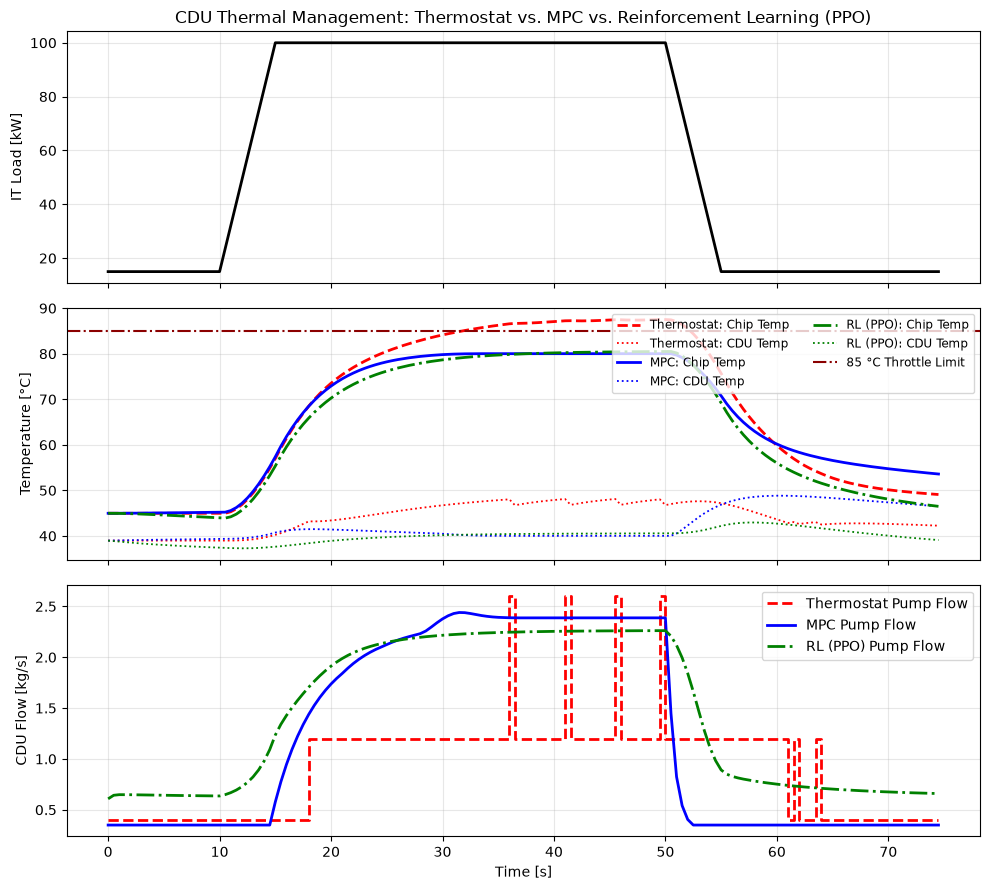

In [3]:
from scipy.optimize import minimize
import matplotlib.pyplot as plt

# ==============================================================================
# Cell 2: Side-by-Side Comparison (Thermostat vs. MPC vs. Trained PyTorch RL)
# ==============================================================================
N_steps = len(t_grid)
u_idle = 0.4
T_cdu0 = T_fac + float(q_bench[0]) / (u_idle * cp)
T_chip0 = T_cdu0 + float(q_bench[0]) * R_th
x0 = np.array([T_chip0, T_cdu0], dtype=np.float64)

# ------------------------------------------------------------------------------
# 1. Classical 3-Stage Thermostat (triggers on CDU coolant temp T_cdu)
# ------------------------------------------------------------------------------
x_therm = x0.copy()
hist_therm = np.zeros((N_steps, 3))  # [T_chip, T_cdu, m_dot]

for k in range(N_steps):
    T_cdu_meas = x_therm[1]
    if T_cdu_meas < 43.0:
        u_curr = 0.4
    elif T_cdu_meas < 48.0:
        u_curr = 1.2
    else:
        u_curr = 2.6
    hist_therm[k] = [x_therm[0], x_therm[1], u_curr]
    x_therm = rk4_step(x_therm, u_curr, float(q_bench[k]), dt)

# ------------------------------------------------------------------------------
# 2. Successive-Linearization MPC (with Q_IT workload feedforward)
# ------------------------------------------------------------------------------
Np = 16
x_mpc = x0.copy()
hist_mpc = np.zeros((N_steps, 3))
u_prev = u_idle

for k in range(N_steps):
    q_curr = float(q_bench[k])
    f0 = cdu_ode(x_mpc, u_prev, q_curr)
    A_c = np.array([
        [-1.0 / (C_chip * R_th),  1.0 / (C_chip * R_th)],
        [ 1.0 / (C_cdu * R_th),  -(1.0 / (C_cdu * R_th) + u_prev * cp / C_cdu)]
    ])
    B_u = np.array([0.0, -cp * (x_mpc[1] - T_fac) / C_cdu])
    B_d = np.array([1.0 / C_chip, 0.0])
    c_0 = f0 - A_c @ x_mpc - B_u * u_prev - B_d * q_curr

    Ad = np.eye(2) + dt * A_c
    Bu_d, Bd_d, cd_d = dt * B_u, dt * B_d, dt * c_0

    def mpc_objective(u_seq):
        x_pred = x_mpc.copy()
        cost = 0.0
        u_last = u_prev
        for j in range(Np):
            u_j = u_seq[j]
            x_pred = Ad @ x_pred + Bu_d * u_j + Bd_d * q_curr + cd_d
            violation = max(0.0, x_pred[0] - T_soft_cap)
            cost += 100.0 * (violation ** 2) + 1.0 * (u_j ** 3) + 3.0 * ((u_j - u_last) ** 2)
            u_last = u_j
        return cost

    res = minimize(
        mpc_objective,
        x0=np.full(Np, u_prev),
        method="L-BFGS-B",
        bounds=[(m_min, m_max)] * Np,
        options={"maxiter": 40}
    )
    u_opt = res.x[0]
    hist_mpc[k] = [x_mpc[0], x_mpc[1], u_opt]
    x_mpc = rk4_step(x_mpc, u_opt, q_curr, dt)
    u_prev = u_opt

# ------------------------------------------------------------------------------
# 3. Deterministic Rollout of Trained RL Agent (`ac` from Cell 1)
# ------------------------------------------------------------------------------
x_rl = x0.copy()
hist_rl = np.zeros((N_steps, 3))
u_prev_rl = u_idle

for k in range(N_steps):
    q_curr = float(q_bench[k])
    obs = np.array([
        (x_rl[0] - 55.0) / 30.0,
        (x_rl[1] - 45.0) / 20.0,
        (q_curr - 50.0) / 50.0,
        (u_prev_rl - 1.5) / 1.5
    ], dtype=np.float32)

    with torch.no_grad():
        act_norm = float(np.clip(ac.actor_mean(torch.tensor(obs)).item(), -1.0, 1.0))
    u_rl = m_min + 0.5 * (act_norm + 1.0) * (m_max - m_min)

    hist_rl[k] = [x_rl[0], x_rl[1], u_rl]
    x_rl = rk4_step(x_rl, u_rl, q_curr, dt)
    u_prev_rl = u_rl

# ------------------------------------------------------------------------------
# 4. Summary Metrics & 3-Panel Comparison Plot
# ------------------------------------------------------------------------------
print(f"Thermostat -> Peak T_chip: {hist_therm[:, 0].max():.2f} °C | Pump Energy Proxy: {np.sum(hist_therm[:, 2]**3)*dt:.1f}")
print(f"Python MPC -> Peak T_chip: {hist_mpc[:, 0].max():.2f} °C | Pump Energy Proxy: {np.sum(hist_mpc[:, 2]**3)*dt:.1f}")
print(f"PyTorch RL -> Peak T_chip: {hist_rl[:, 0].max():.2f} °C | Pump Energy Proxy: {np.sum(hist_rl[:, 2]**3)*dt:.1f}")

fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)

# Panel 1: IT Workload Surge
axes[0].plot(t_grid, q_bench, "k-", lw=2)
axes[0].set_ylabel("IT Load [kW]")
axes[0].set_title("CDU Thermal Management: Thermostat vs. MPC vs. Reinforcement Learning (PPO)")
axes[0].grid(True, alpha=0.3)

# Panel 2: Chip & CDU Coolant Temperatures
axes[1].plot(t_grid, hist_therm[:, 0], "r--", lw=2, label="Thermostat: Chip Temp")
axes[1].plot(t_grid, hist_therm[:, 1], "r:", lw=1.3, label="Thermostat: CDU Temp")
axes[1].plot(t_grid, hist_mpc[:, 0], "b-", lw=2, label="MPC: Chip Temp")
axes[1].plot(t_grid, hist_mpc[:, 1], "b:", lw=1.3, label="MPC: CDU Temp")
axes[1].plot(t_grid, hist_rl[:, 0], "g-.", lw=2, label="RL (PPO): Chip Temp")
axes[1].plot(t_grid, hist_rl[:, 1], "g:", lw=1.3, label="RL (PPO): CDU Temp")
axes[1].axhline(T_throttle, color="darkred", linestyle="-.", lw=1.5, label="85 °C Throttle Limit")
axes[1].set_ylabel("Temperature [°C]")
axes[1].legend(loc="upper right", ncol=2, fontsize=8.5)
axes[1].grid(True, alpha=0.3)

# Panel 3: CDU Pump Mass Flow Rate
axes[2].step(t_grid, hist_therm[:, 2], "r--", where="post", lw=2, label="Thermostat Pump Flow")
axes[2].plot(t_grid, hist_mpc[:, 2], "b-", lw=2, label="MPC Pump Flow")
axes[2].plot(t_grid, hist_rl[:, 2], "g-.", lw=2, label="RL (PPO) Pump Flow")
axes[2].set_ylabel("CDU Flow [kg/s]")
axes[2].set_xlabel("Time [s]")
axes[2].legend(loc="upper right")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()